## <font color = #0288d1>卷积模型与训练</font>

+ ### 卷积神经网络通常具有的架构是：

- ### 卷积层
- ### 激活
- ### 池化


In [1]:
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import Compose, Normalize, ToTensor
from train_cuda import train

In [2]:
mean = torch.tensor(0.1307)
std = torch.tensor(0.3081)
compose = Compose([ToTensor(), Normalize(mean, std)])
train_dataset = datasets.MNIST("./Datasets", train=True, transform=compose, download=False)
test_dataset = datasets.MNIST("./Datasets", train=False, transform=compose, download=False)
train_loader = DataLoader(train_dataset, batch_size=1000, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000)

In [ ]:
class CNN(nn.Module):
    def __init__(self, n_feature, p=0.0):
        super().__init__()
        self.n_feature = n_feature
        self.p = p
        # Creates the convolution layers
        self.conv1 = nn.Conv2d(
            in_channels=1, out_channels=n_feature, 
            kernel_size=3, padding=1
        )
        self.conv2 = nn.Conv2d(
            in_channels=n_feature, out_channels=n_feature, 
            kernel_size=3, padding=1
        )

        self.fc1 = nn.Linear(n_feature * 7 * 7, 392)
        self.fc2 = nn.Linear(392, 196)
        self.fc3 = nn.Linear(196, 98)
        self.fc4 = nn.Linear(98, 10)
        # Creates dropout layers
        self.drop = nn.Dropout(self.p)

    def featurizer(self, x):
        # Featurizer
        # First convolutional block
        # 1@28x28 -> n_feature@28x28 -> n_feature@14x14
        x = self.conv1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        # Second convolutional block
        # n_feature@14x14 -> n_feature@14x14 -> n_feature@7x7
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)

        x = nn.Flatten()(x)
        return x

    def classifier(self, x):

        if self.p > 0:
            x = self.drop(x)
        x = self.fc1(x)
        x = F.relu(x)
        if self.p > 0:
            x = self.drop(x)
        x = self.fc2(x)
        x = F.relu(x)
        if self.p > 0:
            x = self.drop(x)
        x = self.fc3(x)
        x = F.relu(x)
        if self.p > 0:
            x = self.drop(x)
        x = self.fc4(x)
        return x

    def forward(self, x):
        x = self.featurizer(x)
        x = self.classifier(x)
        return x

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN(16, 0.3).to(device)
lr = 3e-4
epochs = 50
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)
train_loss, val_loss = train(
    model, train_loader, test_loader, loss_fn, optimizer, epochs, device
)

Epoch 1/50 - loss: 1.6771 - val_loss: 0.6366
Epoch 2/50 - loss: 0.6089 - val_loss: 0.2708
Epoch 3/50 - loss: 0.3664 - val_loss: 0.1813
Epoch 4/50 - loss: 0.2692 - val_loss: 0.1340
Epoch 5/50 - loss: 0.2112 - val_loss: 0.1060
Epoch 6/50 - loss: 0.1794 - val_loss: 0.0885
Epoch 7/50 - loss: 0.1566 - val_loss: 0.0753
Epoch 8/50 - loss: 0.1410 - val_loss: 0.0674
Epoch 9/50 - loss: 0.1245 - val_loss: 0.0594
Epoch 10/50 - loss: 0.1173 - val_loss: 0.0568
Epoch 11/50 - loss: 0.1093 - val_loss: 0.0504
Epoch 12/50 - loss: 0.1003 - val_loss: 0.0457
Epoch 13/50 - loss: 0.0911 - val_loss: 0.0455
Epoch 14/50 - loss: 0.0870 - val_loss: 0.0415
Epoch 15/50 - loss: 0.0831 - val_loss: 0.0405
Epoch 16/50 - loss: 0.0758 - val_loss: 0.0365
Epoch 17/50 - loss: 0.0759 - val_loss: 0.0363
Epoch 18/50 - loss: 0.0744 - val_loss: 0.0334
Epoch 19/50 - loss: 0.0698 - val_loss: 0.0338
Epoch 20/50 - loss: 0.0657 - val_loss: 0.0333
Epoch 21/50 - loss: 0.0633 - val_loss: 0.0317
Epoch 22/50 - loss: 0.0619 - val_loss: 0.03

In [ ]:
import matplotlib.pyplot as plt

plt.style.use("fivethirtyeight")


def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_loss, label="Training Loss", c="b")
    plt.plot(val_loss, label="Validation Loss", c="r")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    return fig


fig = plot_losses()

In [5]:
import torchmetrics

accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
for x, y in test_loader:
    x, y = x.to(device), y.to(device)
    yhat = model(x)
    accuracy(yhat, y)
accuracy.compute()
print(f"Test Accuracy: {accuracy.compute().item() * 100:.2f}%")

Test Accuracy: 99.16%


/tmp/ipykernel_838312/3353743475.py:35: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  img = wrong_imgs[i][0] * std.numpy() + mean.numpy()


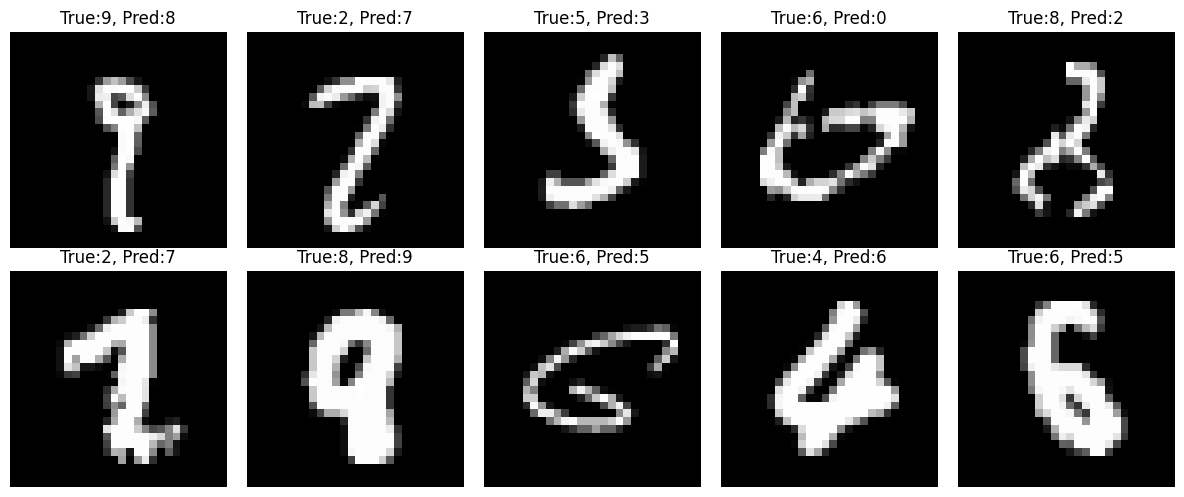

In [7]:
import matplotlib.pyplot as plt
# ========== 追加：找出测试集前10个识别错误的样本并绘图 ==========
model.eval()
wrong_imgs = []
wrong_labels_true = []
wrong_labels_pred = []

with torch.inference_mode():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        pred = torch.argmax(logits, dim=1)

        # 找出本batch里预测不等于真值的索引
        mask = pred != y
        wrong_x_batch = x[mask]
        wrong_y_true_batch = y[mask]
        wrong_y_pred_batch = pred[mask]

        # 逐个加入，凑够10张就停
        for img, yt, yp in zip(wrong_x_batch, wrong_y_true_batch, wrong_y_pred_batch):
            wrong_imgs.append(img.cpu())
            wrong_labels_true.append(yt.item())
            wrong_labels_pred.append(yp.item())
            if len(wrong_imgs) >= 10:
                break
        if len(wrong_imgs) >= 10:
            break

# 绘图
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i+1)
    # 反归一化：img = img * std + mean
    img = wrong_imgs[i][0] * std.numpy() + mean.numpy()
    plt.imshow(img, cmap="gray")
    plt.title(f"True:{wrong_labels_true[i]}, Pred:{wrong_labels_pred[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()
